# Más allá: exposición conciliada con un motor de referencia dentro del error de Monte Carlo y valores de referencia para el riesgo de correlación adversa

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 03, 06 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la afirmación BS-2 del SDD para el motor de contraparte, qué cubre y qué no afirma;
- recalcular la exposición del motor y compararla con el perfil versionado de ORE 1.8.17.0 dentro de errores estándar combinados de Monte Carlo, para las dos variantes donde la afirmación se cumple;
- leer las otras variantes como brechas informadas, con la cifra que dice qué tan grande es cada una;
- verificar las formas cerradas contra las filas de QuantLib, y la calibración de correlación adversa contra los dígitos impresos del Apéndice del artículo;
- decir por qué una conciliación que informa sus fallas es una evidencia más fuerte que una que informa solo sus éxitos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw
from riskvalidation.validation import ccr as vc

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Las seis variantes del caso C12 (riesgo de crédito de contraparte) bajo `data/derived/C12/`, sobre swaps sintéticos y la curva a la par del Tesoro de EE. UU. del 2025-09-30 (clase de licencia `mirror-allowed`). Cada una lleva el bloque `ore_reconciliation` (ORE 1.8.17.0, corrido de forma nativa sobre las mismas operaciones y curva con 10.000 muestras antitéticas; no se corre aquí) y las pruebas del motor. Los cuadernos 06 y 07 explican cada prueba; este las lee como evidencia de una afirmación.

- **Archivos que se leen:** los seis documentos `single-swap.json`, `netting-set.json`, `csa-mpor-10d.json`, `csa-mpor-20d.json`, `with-im.json` y `wrong-way-risk.json`.
- **Qué se recalcula en vivo:** la exposición esperada del motor para el swap único y para el conjunto de neteo, desde la curva, la calibración, la semilla y el número de trayectorias versionados (cuaderno 01), y la comparación con el perfil versionado de ORE; la calibración de correlación adversa del Apéndice del artículo.
- **Qué se lee:** los perfiles de ORE y las filas de comparación con QuantLib.

La celda siguiente carga los documentos y verifica que cada archivo versionado que cita la afirmación existe y fue calculado con la versión del motor instalada aquí.

In [2]:
# Cargar las seis variantes versionadas de C12 (el cuaderno está tres carpetas bajo la raíz del repositorio) y verificar los archivos, la versión de cálculo y la clase de licencia
ROOT = Path("../../..").resolve()
names = ["single-swap", "netting-set", "csa-mpor-10d", "csa-mpor-20d", "with-im", "wrong-way-risk"]
paths = {n: ROOT / "data" / "derived" / "C12" / f"{n}.json" for n in names}
docs = {n: json.loads(p.read_text(encoding="utf-8")) for n, p in paths.items()}

print("archivos presentes:", ("sí" if all(p.is_file() for p in paths.values()) else "no"), "| motor instalado:", rv.__version__)
print("calculado con riskvalidation, por variante:", {n: d["provenance"]["riskvalidation_version"] for n, d in docs.items()})
print("estado de verdad:", {d["provenance"]["truth_status"] for d in docs.values()}, "| clases de licencia de las entradas:", docs["single-swap"]["provenance"]["licence_classes"])
print("versión de ORE:", docs["single-swap"]["outputs"]["ore_reconciliation"]["ore_version"])

archivos presentes: sí | motor instalado: 0.9.0
calculado con riskvalidation, por variante: {'single-swap': '0.9.0', 'netting-set': '0.9.0', 'csa-mpor-10d': '0.9.0', 'csa-mpor-20d': '0.9.0', 'with-im': '0.9.0', 'wrong-way-risk': '0.9.0'}
estado de verdad: {'synthetic-calibrated'} | clases de licencia de las entradas: {'treasury-par-curve': 'mirror-allowed', 'treasury-hqm': 'mirror-allowed'}
versión de ORE: 1.8.17.0


## Método

### Paso 1: el lado del motor, recalculado

Para que la afirmación signifique algo el lado del motor no puede ser un número copiado de un archivo. Reconstruimos la exposición esperada del swap único y del conjunto de neteo desde la curva, la calibración, la semilla y el número de trayectorias (la construcción del cuaderno 01, con la misma grilla de tiempo), en la medida forward a la que se lleva el perfil descontado de ORE. La celda siguiente lo hace y verifica que el perfil reconstruido es igual al versionado, de modo que lo que comparamos con ORE es lo que el producto informa.

In [3]:
# Reconstruir la simulación del cuaderno 01 y la EE del swap único y del conjunto de neteo, y verificarlas contra los perfiles versionados
base = docs["netting-set"]["outputs"]
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
report = np.array(named["time_grid_years"]["value"])
main = np.concatenate([[0.0], report])
swaps = [sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer", t["start_years"], t["maturity_years"],
                 t["fixed_frequency_per_year"]) for t in base["book"]["trades"]]
merged = np.unique(np.round(np.concatenate([main] + [main + d for d in (14 / 360, 28 / 360)]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)
p0r, nm = p0(report), numeraire[:, ix]

live = {}
for key, members in (("single-swap", [0]), ("netting-set", [0, 1, 2, 3])):
    e_d, e_se = ex.expected_exposure(ex.net_values(values[members][:, :, ix]), nm)
    live[key] = (e_d / p0r, e_se / p0r)
    committed = np.array(docs[key]["outputs"]["exposure"]["ee"]["values"])
    print(f"{key:12s} mayor brecha entre la EE reconstruida y la versionada:", float(np.max(np.abs(live[key][0] - committed))))

single-swap  mayor brecha entre la EE reconstruida y la versionada: 0.0
netting-set  mayor brecha entre la EE reconstruida y la versionada: 0.0


### Paso 2: la conciliación con ORE

Ahora el perfil reconstruido del motor se enfrenta al versionado de ORE, punto a punto, con `reconcile_ee_profile` del motor, cada lado con su propio error de Monte Carlo. Esta es la afirmación en su forma más nítida: dos implementaciones independientes, una en Python y una en C++, del mismo modelo de Hull-White sobre la misma curva y operaciones, con la diferencia medida en unidades de su propio ruido. Para la EEPE y el CVA el error combinado es el registrado en el documento. La celda siguiente imprime, para las dos variantes de la afirmación, el estadístico, el número de fechas dentro del umbral, y las diferencias de EEPE y CVA.

In [4]:
# Conciliar la EE reconstruida de las dos variantes con el perfil versionado de ORE, y leer las diferencias de EEPE y CVA en errores estándar combinados
print(f"{'variante':13s}{'estadístico':>12s}{'fechas dentro de 2 ee':>24s}{'luz':>7s}{'EEPE (ee)':>12s}{'CVA (ee)':>11s}")
for key in ("single-swap", "netting-set"):
    o = docs[key]["outputs"]["ore_reconciliation"]
    ref, ref_se = np.array(o["ore_ee"]["values"]), np.array(o["ore_ee"]["mc_se"])
    t = vc.reconcile_ee_profile(live[key][0], live[key][1], ref, ref_se, k_se=2.0)
    inside = int(np.sum(np.abs(live[key][0] - ref) <= 2.0 * np.sqrt(live[key][1] ** 2 + ref_se**2)))
    e, c = o["eepe_agreement"], o["cva_agreement"]
    print(f"{key:13s}{t.statistic:12.3f}{inside:20d} /{report.size:3d}{t.light.value:>7s}{e['difference'] / e['combined_se']:12.2f}{c['difference'] / c['combined_se']:11.2f}")
print("umbral (k_se):", t.extras["thresholds"]["k_se"], "| test_id:", t.test_id)

variante      estadístico   fechas dentro de 2 ee    luz   EEPE (ee)   CVA (ee)
single-swap         0.775                  33 / 33  green        0.30       0.37
netting-set         0.715                  33 / 33  green        0.31       0.40
umbral (k_se): 2.0 | test_id: ccr.reconcile_ee_profile


### Paso 3: las brechas, informadas

La afirmación cubre las variantes donde la conciliación se cumple, y el documento informa las otras. La celda siguiente lee las seis variantes y las ordena con la regla del propio documento: conciliada, brecha informada o no aplicable. Para cada una muestra el número de fechas de EE dentro del umbral, las diferencias de EEPE y CVA en errores estándar combinados, y para la variante con margen inicial la razón de los dos DIM medios. Nada se oculta promediando: se imprime la mayor brecha de cada perfil.

In [5]:
# Ordenar las seis variantes con la regla del propio documento e imprimir el tamaño de cada brecha informada
claimed, gaps, na = [], [], []
print(f"{'variante':15s}{'veredicto':16s}{'fechas EE en 2 ee':>20s}{'mayor brecha EE (ee)':>24s}{'EEPE (se)':>11s}{'CVA (se)':>10s}")
for n in names:
    o = docs[n]["outputs"]
    rec = o["ore_reconciliation"]
    if rec["status"] == "not-applicable":
        na.append(n)
        print(f"{n:15s}{'no aplicable':16s}")
        continue
    ag = rec["agreement"]
    inside = sum(p["within_two_se"] for p in ag)
    gap_max = max(abs(p["difference"]) / p["combined_se"] for p in ag)
    verdict = "afirmada" if rec["all_within_two_se"] else "brecha informada"
    (claimed if rec["all_within_two_se"] else gaps).append(n)
    e, c = rec["eepe_agreement"], rec["cva_agreement"]
    print(f"{n:15s}{verdict:16s}{inside:16d} /{len(ag):3d}{gap_max:24.1f}{e['difference'] / e['combined_se']:11.2f}{c['difference'] / c['combined_se']:10.2f}")
print("afirmadas:", claimed, "| brecha informada:", gaps, "| no aplicable:", na)
dim = docs["with-im"]["outputs"]["ore_reconciliation"]["dim_agreement"]
print("margen inicial: puntos del DIM medio dentro del umbral:", sum(p["within_two_se"] for p in dim), "de", len(dim),
      "| razón DIM medio de ORE / motor:", round(float(np.mean(np.array(docs["with-im"]["outputs"]["ore_reconciliation"]["ore_dim"]["values"]) / np.array(docs["with-im"]["outputs"]["initial_margin"]["dim"]["values"]))), 3))
print("hallazgos que el caso registra contra ORE (variante: títulos):")
for n in gaps:
    print(" ", n, [f["title"]["es"][:70] for f in docs[n]["findings"] if "ORE" in f["title"]["en"]])

variante       veredicto          fechas EE en 2 ee    mayor brecha EE (ee)  EEPE (se)  CVA (se)
single-swap    afirmada                      33 / 33                     0.8       0.30      0.37
netting-set    afirmada                      33 / 33                     0.7       0.31      0.40
csa-mpor-10d   brecha informada              17 / 33                     9.9      -1.55    -15.89
csa-mpor-20d   brecha informada              21 / 33                     7.1      -2.20     -9.88
with-im        brecha informada              32 / 33                    11.7      -0.71     -1.40
wrong-way-risk no aplicable    
afirmadas: ['single-swap', 'netting-set'] | brecha informada: ['csa-mpor-10d', 'csa-mpor-20d', 'with-im'] | no aplicable: ['wrong-way-risk']
margen inicial: puntos del DIM medio dentro del umbral: 0 de 33 | razón DIM medio de ORE / motor: 0.884
hallazgos que el caso registra contra ORE (variante: títulos):
  csa-mpor-10d ['1 fila(s) red sobre el CVA frente a ORE 1.8.17.0', '1 fi

### Paso 4: las otras referencias

Otras dos referencias respaldan la afirmación. Primero, las formas cerradas del modelo de Hull-White contra QuantLib 1.44, como cuatro filas con ambos valores y un umbral de $10^{-6}$ en términos relativos. Segundo, la variante de correlación adversa no tiene referencia en ORE, porque el ejemplo de ORE es otro modelo; su referencia es el Apéndice de Hull y White (2012), que imprime una calibración de tres trayectorias. Los dígitos del artículo son los valores de referencia: el $a(t^*)$ impreso y las tasas de riesgo $h_{ij}$. `wwr_calibrate_a`, del motor, debe darlos, y en $b=0$ `wwr_cva` debe devolver el CVA independiente de forma exacta. La celda siguiente verifica las cuatro cosas.

In [6]:
# Las cuatro filas de QuantLib, los valores de referencia del Apéndice contra el motor, y la identidad en b = 0 del CVA de correlación adversa
ql = [row for row in docs["single-swap"]["tests"] if row["test_id"].startswith("ccr.quantlib")]
rel = [abs(row["extras"]["engine"] - row["extras"]["quantlib"]) / abs(row["extras"]["quantlib"]) for row in ql]
print("filas de QuantLib:", len(ql), "| mayor diferencia relativa:", f"{max(rel):.2e}", "| el umbral 1e-6 se cumple:", ("sí" if max(rel) < 1e-6 else "no"), "| luces:", {row["light"] for row in ql})

w_app = np.array([[100.0, 100.0], [200.0, 300.0], [300.0, 400.0]])
target = cva.survival_from_spread(np.array([0.01, 0.01]), np.array([0.5, 1.0]), 1.0)
a_app, h_app = cva.wwr_calibrate_a(w_app, target, np.array([0.5, 0.5]), 0.01)
printed_a = np.array([-6.9128, -7.8509])
printed_h = np.array([[0.00270, 0.00735, 0.01998], [0.00106, 0.00782, 0.02126]])
unit_a, unit_h = 1e-4, 1e-5
print("a(t*) brecha con los dígitos impresos, en unidades del último dígito impreso:", np.round(np.abs(a_app - printed_a) / unit_a, 2))
print("h mayor brecha, en unidades del último dígito impreso:", round(float(np.max(np.abs(h_app.T - printed_h)) / unit_h), 2))
print("la supervivencia promedio tras cada paso es igual a la meta:", ("sí" if np.allclose(np.exp(-np.cumsum(h_app * 0.5, axis=1)).mean(axis=0), target, rtol=0, atol=1e-12) else "no"))

wwr = docs["wrong-way-risk"]["outputs"]
credit = wwr["cva_dva"]
survival = np.array([b["survival"] for b in credit["buckets"]])
dt = np.diff(np.concatenate([[0.0], report]))
v_net = ex.net_values(values[:, :, ix])
w, x_disc = v_net / 1e6, np.maximum(v_net, 0.0) / nm
independent = wwr["cva_dva"]["cva"]["amount"]
value0, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], 0.0)
print("el CVA de correlación adversa en b = 0 es igual al CVA independiente de forma exacta:", ("sí" if value0 == independent else "no"))
for row in wwr["wrong_way_risk"]["sweep"][2:4]:
    value, _ = cva.wwr_cva(w, x_disc, survival, dt, credit["lgd"], row["b"])
    print(f"b = {row['b']:.0f} | CVA {value:10.2f} | versionado {row['cva']['amount']:10.2f} | cambio vs independiente {value / independent - 1:+.1%}")

filas de QuantLib: 4 | mayor diferencia relativa: 9.50e-08 | el umbral 1e-6 se cumple: sí | luces: {'green'}
a(t*) brecha con los dígitos impresos, en unidades del último dígito impreso: [0.33 1.32]
h mayor brecha, en unidades del último dígito impreso: 0.45
la supervivencia promedio tras cada paso es igual a la meta: sí
el CVA de correlación adversa en b = 0 es igual al CVA independiente de forma exacta: sí
b = 1 | CVA   12439.56 | versionado   12439.56 | cambio vs independiente +31.2%
b = 2 | CVA   15594.61 | versionado   15594.61 | cambio vs independiente +64.5%


La última celda dibuja la afirmación como una figura. A la izquierda, la mayor brecha estandarizada entre el motor y ORE para el perfil de EE de cada variante, en escala logarítmica, contra el umbral de dos errores estándar: las variantes afirmadas están bajo la línea, las brechas informadas sobre ella. A la derecha, la brecha estandarizada a lo largo de las fechas para el swap único y el CSA de 10 días.

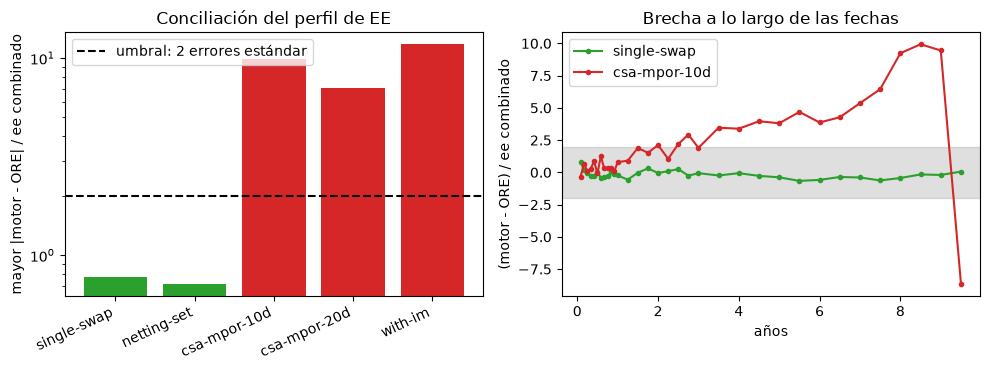

In [7]:
# Dibujar la mayor brecha estandarizada de EE por variante contra el umbral (izquierda) y la brecha a lo largo de las fechas para dos variantes (derecha)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
checked = [n for n in names if n not in na]
worst = [max(abs(p["difference"]) / p["combined_se"] for p in docs[n]["outputs"]["ore_reconciliation"]["agreement"]) for n in checked]
colors = ["tab:green" if n in claimed else "tab:red" for n in checked]
left.bar(range(len(checked)), worst, color=colors)
left.axhline(2.0, color="black", ls="--", label="umbral: 2 errores estándar")
left.set_yscale("log")
left.set_xticks(range(len(checked)))
left.set_xticklabels(checked, rotation=25, ha="right")
left.set_ylabel("mayor |motor - ORE| / ee combinado")
left.set_title("Conciliación del perfil de EE")
left.legend()
for n, color in (("single-swap", "tab:green"), ("csa-mpor-10d", "tab:red")):
    ag = docs[n]["outputs"]["ore_reconciliation"]["agreement"]
    right.plot([p["t"] for p in ag], [-p["difference"] / p["combined_se"] for p in ag], "o-", ms=3, color=color, label=n)
right.axhspan(-2, 2, color="grey", alpha=0.25)
right.set_xlabel("años")
right.set_ylabel("(motor - ORE) / ee combinado")
right.set_title("Brecha a lo largo de las fechas")
right.legend()
fig.tight_layout()
plt.show()

## Estado del arte

Qué ofrece la práctica, tal como la investigación persistida del caso la registra desde las fuentes primarias. Las herramientas de exposición de contraparte dan los estimadores y la simulación y dejan la conciliación al usuario: ORE es el motor abierto más completo y la referencia natural, y QuantLib aporta las formas cerradas del modelo de Hull-White; ninguno trae una declaración de cuánto coincide con él una implementación independiente. La regla de la propia investigación para Contraste es que los números de ORE y de QuantLib pueden presentarse como una validación del producto **solo hasta donde llegan las conciliaciones realmente corridas**, nunca más allá. La práctica de ingeniería detrás de una conciliación es la que se usa en este tema: ambos lados llevan un error de Monte Carlo, la diferencia se enuncia en errores estándar combinados, y se fija un umbral antes de la comparación, aquí dos errores estándar combinados, un umbral interno de Contraste y no uno regulatorio.

## Más allá del estado del arte

Este cuaderno demuestra la afirmación **BS-2** del SDD, para el motor de contraparte: las conciliaciones contra motores de referencia que existen hoy, y la brecha informada.

- **Qué se afirma.** La exposición del motor para el swap único y para el conjunto de neteo coincide con ORE 1.8.17.0 en cada una de las 33 fechas del informe dentro de dos errores estándar combinados de Monte Carlo, y también la EEPE y el CVA. Las opciones sobre bonos y las swaptions de Hull-White del motor coinciden con QuantLib 1.44 a un $10^{-6}$ relativo. La calibración de correlación adversa reproduce los valores impresos del Apéndice de Hull y White (2012): las tasas de riesgo a media unidad del último dígito impreso y el $a(t^*)$ impreso a 1,4 unidades.
- **Qué se informa como brecha y no se afirma.** Las variantes con garantía (CSA de 10 y de 20 días) y la variante con margen inicial no coinciden con ORE: las mayores brechas del perfil de EE son 9,9, 7,1 y 11,7 errores estándar combinados, el CVA difiere en 15,9 y 9,9 errores estándar en las dos variantes de CSA, y el margen inicial dinámico medio de ORE es 0,88 del del motor. El documento las registra como hallazgos con una causa identificada en parte (el monto mínimo de transferencia) y abierta en parte.
- **Qué no se afirma en absoluto.** La variante de correlación adversa contra ORE (otro modelo: no hay referencia), y el modelo contra el mercado (cuaderno 06: se rechaza).
- **Por qué esto va más allá.** La investigación encontró herramientas que traen estimadores y dejan la conciliación al usuario, y una regla de que los números de motores de referencia no deben afirmarse más allá de las conciliaciones realmente corridas. Contraste las corre, a la vista, con las fallas impresas junto a los éxitos, sobre archivos versionados que cualquiera puede reabrir.

La evidencia está en los documentos versionados (listados en la afirmación del SDD), y cada número de arriba lo imprimen las celdas de este cuaderno.

## Resultados

- **El lado del motor es el del producto.** La exposición esperada del swap único y del conjunto de neteo reconstruida aquí desde la curva, la calibración, la semilla y el número de trayectorias es igual al perfil versionado de forma exacta (brecha 0,0), así que lo que se compara con ORE es lo que informa el producto.
- **Donde la afirmación se cumple.** Contra ORE 1.8.17.0, el swap único tiene un estadístico de 0,775 errores estándar combinados y el conjunto de neteo de cuatro swaps 0,715, con las 33 fechas dentro del umbral de 2. La EEPE difiere en 0,30 y 0,31 errores estándar y el CVA en 0,37 y 0,40. El motor corrió 20.000 trayectorias; ORE corrió 10.000 muestras antitéticas de forma nativa en cerca de medio minuto.
- **Donde no, y por cuánto.** El CSA de 10 días tiene 17 de 33 fechas dentro del umbral y una mayor brecha de 9,9 errores estándar, una EEPE dentro del umbral (-1,55) y un CVA a 15,9 errores estándar (ORE es menor). El CSA de 20 días tiene 21 de 33 fechas dentro, una mayor brecha de 7,1, y tanto la EEPE (-2,20) como el CVA (-9,88) fuera del umbral. Con margen inicial 32 de 33 fechas de EE están dentro del umbral (mayor brecha 11,7, en una fecha), la EEPE y el CVA coinciden (-0,71 y -1,40), y ninguno de los 33 puntos del margen inicial dinámico medio lo hace: el de ORE es en promedio 0,884 del del motor. El caso registra cada una como un hallazgo.
- **Formas cerradas y valores de referencia.** Las cuatro filas de QuantLib coinciden con un relativo de 9,5e-8 como máximo, dentro del umbral de 1e-6. La calibración de correlación adversa reproduce las tasas de riesgo del Apéndice del artículo a 0,45 de una unidad del último dígito impreso, el $a(t_1^*)$ impreso a 0,33 y el $a(t_2^*)$ impreso a 1,32 unidades (el artículo imprime -7,8509 y la raíz de su propia ecuación, que el motor encuentra, se redondea a -7,8508); la supervivencia promedio es igual a la meta a 1e-12. En $b=0$ el CVA de correlación adversa es el CVA independiente de forma exacta, y con $b=1$ y $b=2$ está 31,2% y 64,5% sobre él, igual al barrido versionado.
- **Qué es la afirmación.** Dos de las seis variantes concilian con el motor de referencia dentro del error de Monte Carlo; tres no y lo dicen; una no tiene referencia. Quien quiera cuestionar la afirmación tiene los perfiles de ambos motores en los documentos versionados y el umbral en la prueba del motor.

Lo que este cuaderno no muestra: por qué difieren las variantes con garantía (el monto mínimo de transferencia explica la mayor parte de la brecha del CSA en el documento, y la causa restante y la diferencia del DIM están abiertas), una conciliación de los otros motores del producto (cartera, IRRBB, liquidez) con una referencia, ni una afirmación de que el modelo de Hull-White describe el mercado (cuaderno 06: el backtest lo rechaza).

## Resumen

- BS-2 para el motor de contraparte: la exposición del swap único y del conjunto de neteo coincide con ORE 1.8.17.0 en cada fecha dentro de dos errores estándar combinados, y con QuantLib 1.44 en las formas cerradas.
- La misma conciliación informa sus fallas: las variantes de CSA y el margen inicial dinámico difieren de ORE, con el tamaño de cada brecha impreso y los hallazgos registrados.
- La calibración de correlación adversa no tiene referencia en ORE, así que sus valores de referencia son los dígitos impresos del Apéndice del artículo, igualados a cerca de una unidad del último dígito, y la identidad en $b=0$.
- Una conciliación es evidencia sobre dos implementaciones de un modelo; no dice nada sobre si el modelo se ajusta al mercado.

**Qué probar después.** Aprieta el umbral a 1 error estándar y cuenta qué variantes siguen afirmadas; lista los hallazgos de cada documento y compara sus títulos con las brechas impresas aquí. Este es el último cuaderno del tema.

## Referencias

- Open Source Risk Engine (ORE), release 1.8.17.0. https://github.com/OpenSourceRisk/Engine
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- QuantLib, the open-source quantitative finance library. https://github.com/lballabio/QuantLib
- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6